# TRABALHO 3 — PARTE 2: Árvores de Decisão e Random Forest

Aplicação dos algoritmos de Árvore de Decisão e Random Forest às bases de risco de crédito.

## Importação das bibliotecas

In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

# 1 — Importação dos dados pré-processados

O arquivo `risco_credito.pkl`, produzido na Parte 1, contém a matriz de atributos já codificada e o vetor de classes.

In [2]:
pasta_parte_2 = Path.cwd()
if (pasta_parte_2 / 'Parte-2').exists():
    pasta_parte_2 = pasta_parte_2 / 'Parte-2'
caminho_risco = pasta_parte_2.parent / 'Parte-1' / 'risco_credito.pkl'
if not caminho_risco.exists() and (pasta_parte_2 / 'risco_credito.pkl').exists():
    caminho_risco = pasta_parte_2 / 'risco_credito.pkl'
if not caminho_risco.exists():
    raise FileNotFoundError('Arquivo risco_credito.pkl não encontrado na Parte-1.')

with caminho_risco.open('rb') as arquivo:
    X_risco_credito, y_risco_credito = pickle.load(arquivo)

print('X risco:', X_risco_credito.shape)
print('y risco:', y_risco_credito.shape)

X risco: (14, 4)
y risco: (14,)


# 2 — Árvore de Decisão na base de risco de crédito

## a) e b) Criação e treinamento com o critério de entropia

In [3]:
arvore_risco_credito = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_risco_credito.fit(X_risco_credito, y_risco_credito)
print('Árvore treinada com sucesso.')

Árvore treinada com sucesso.


## c) Importância dos atributos

`feature_importances_` informa a participação relativa de cada atributo na redução da impureza da árvore.

In [4]:
atributos_risco = ['historia', 'divida', 'garantias', 'renda']
importancias_risco = pd.Series(
    arvore_risco_credito.feature_importances_,
    index=atributos_risco,
    name='importancia'
).sort_values(ascending=False)
display(importancias_risco.to_frame())
print('Maior ganho de informação:', importancias_risco.index[0])

,importancia
renda,0.483143
historia,0.336208
divida,0.141795
garantias,0.038854


Maior ganho de informação: renda


O atributo com maior ganho de informação é **renda**, seguido por `historia`, `divida` e `garantias`.

## d) Visualização da árvore

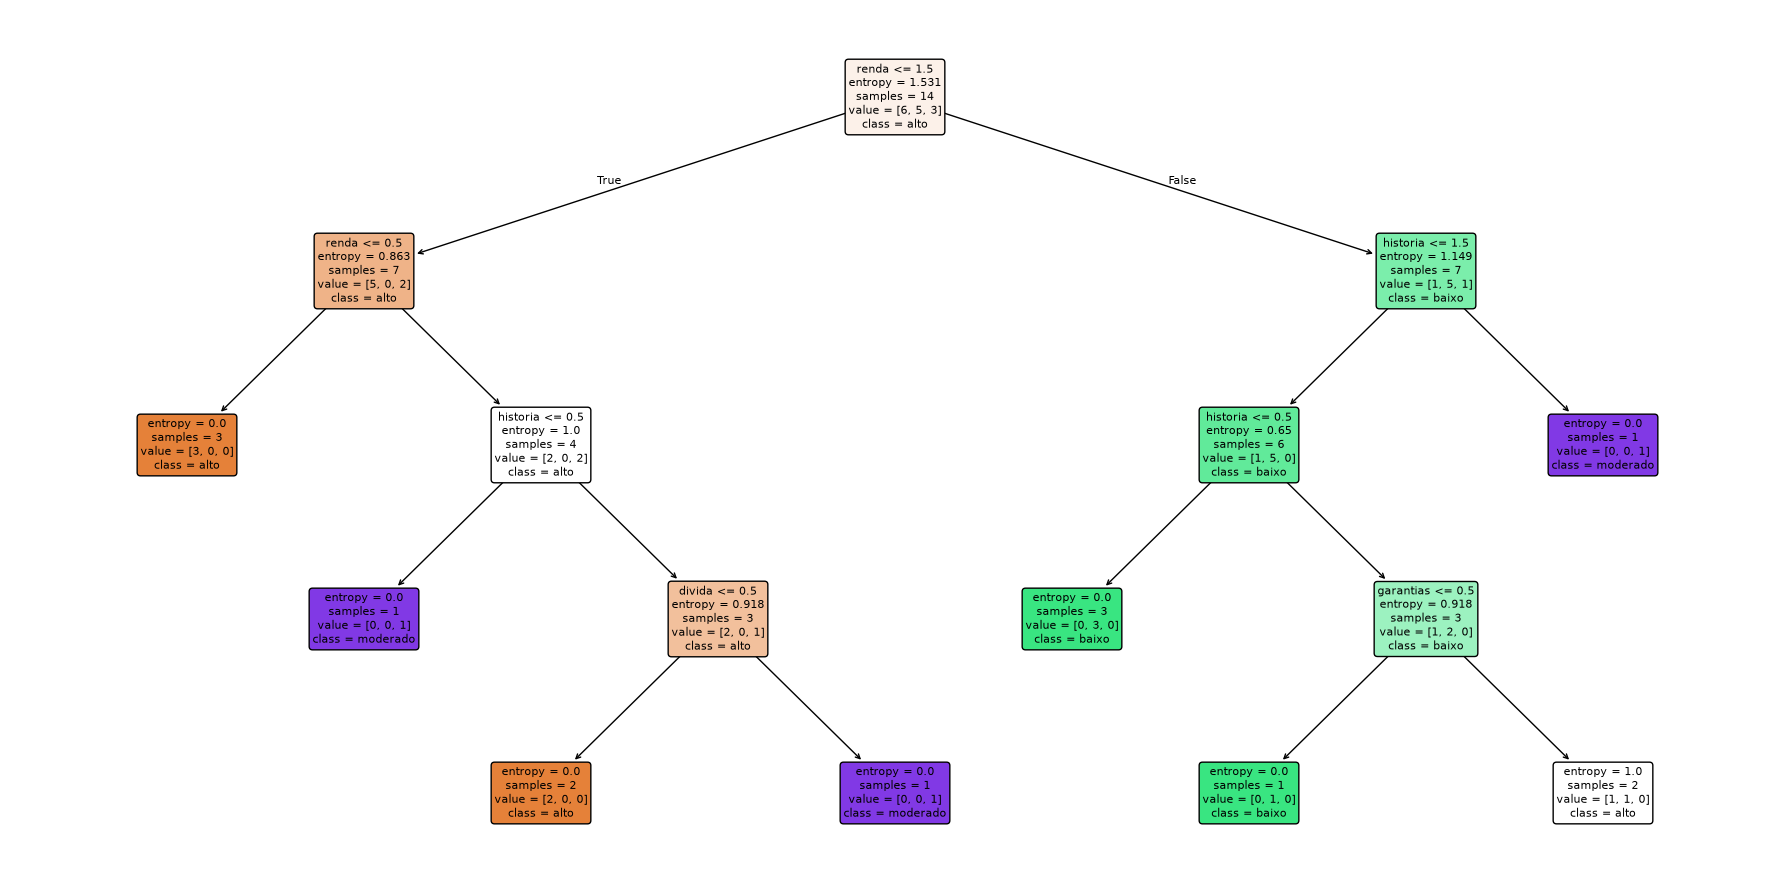

In [5]:
figura, eixo = plt.subplots(figsize=(18, 9))
tree.plot_tree(
    arvore_risco_credito,
    feature_names=atributos_risco,
    class_names=[str(classe) for classe in arvore_risco_credito.classes_],
    filled=True, rounded=True, fontsize=8, ax=eixo
)
figura.tight_layout()
figura.savefig(pasta_parte_2 / 'arvore_risco_credito.png', dpi=140, bbox_inches='tight')
plt.show()

## e) Previsão dos dois clientes

In [6]:
# Códigos definidos pelo LabelEncoder da Parte 1.
novos_clientes = np.array([
    [0, 0, 1, 2],  # boa, alta, nenhuma, acima_35
    [2, 0, 0, 0]   # ruim, alta, adequada, 0_15
])
previsoes_risco = arvore_risco_credito.predict(novos_clientes)
pd.DataFrame({'cliente': ['i', 'ii'], 'previsao': previsoes_risco})

,cliente,previsao
0,i,baixo
1,ii,alto


A Árvore de Decisão classificou o cliente **i** como risco **baixo** e o cliente **ii** como risco **alto**. Modelos diferentes podem produzir resultados diferentes porque aprendem regras distintas.

# 3 — Árvore de Decisão na base Credit Data

## a) Leitura e dimensões dos conjuntos de treinamento e teste

In [7]:
caminho_credit = pasta_parte_2 / 'credit.pkl'
if not caminho_credit.exists():
    raise FileNotFoundError('Coloque credit.pkl na mesma pasta do notebook.')

with caminho_credit.open('rb') as arquivo:
    X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(arquivo)

print('X treinamento:', X_credit_treinamento.shape)
print('y treinamento:', y_credit_treinamento.shape)
print('X teste:', X_credit_teste.shape)
print('y teste:', y_credit_teste.shape)

X treinamento: (1500, 3)
y treinamento: (1500,)
X teste: (500, 3)
y teste: (500,)


## b) Treinamento da Árvore de Decisão

In [8]:
arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_credit_treinamento, y_credit_treinamento)
print('Árvore treinada com sucesso.')

Árvore treinada com sucesso.


## c) Previsões no conjunto de teste

In [9]:
previsoes_arvore = arvore_credit.predict(X_credit_teste)
comparacao_arvore = pd.DataFrame({
    'real': y_credit_teste,
    'previsao': previsoes_arvore,
    'correto': y_credit_teste == previsoes_arvore
})
comparacao_arvore.head(20)

,real,previsao,correto
0,1,1,True
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


## d) Acurácia

In [10]:
acuracia_arvore = accuracy_score(y_credit_teste, previsoes_arvore)
print(f'Acurácia da Árvore de Decisão: {acuracia_arvore:.4f} ({acuracia_arvore:.2%})')

Acurácia da Árvore de Decisão: 0.9820 (98.20%)


## e) Matriz de confusão

[[430   6]
 [  3  61]]
Pagantes classificados corretamente: 430
Pagantes classificados incorretamente como não pagantes: 6
Não pagantes classificados corretamente: 61
Não pagantes classificados incorretamente como pagantes: 3


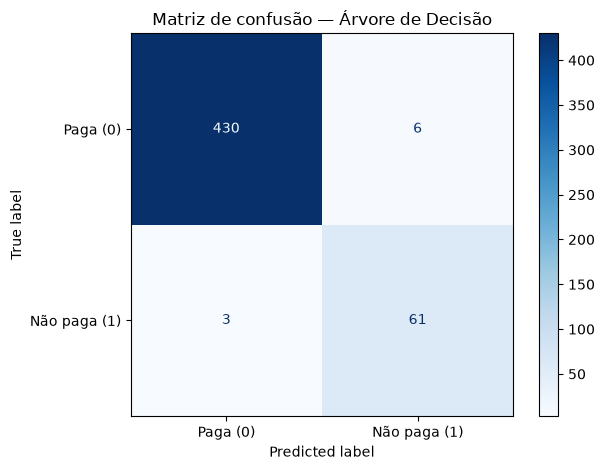

In [11]:
matriz_arvore = confusion_matrix(y_credit_teste, previsoes_arvore, labels=[0, 1])
vn, fp, fn, vp = matriz_arvore.ravel()
print(matriz_arvore)
print(f'Pagantes classificados corretamente: {vn}')
print(f'Pagantes classificados incorretamente como não pagantes: {fp}')
print(f'Não pagantes classificados corretamente: {vp}')
print(f'Não pagantes classificados incorretamente como pagantes: {fn}')

disp = ConfusionMatrixDisplay(matriz_arvore, display_labels=['Paga (0)', 'Não paga (1)'])
disp.plot(cmap='Blues', values_format='d')
disp.ax_.set_title('Matriz de confusão — Árvore de Decisão')
disp.figure_.tight_layout()
disp.figure_.savefig(pasta_parte_2 / 'matriz_confusao_arvore_credit.png', dpi=140, bbox_inches='tight')
plt.show()

## f) Relatório de classificação

In [12]:
print(classification_report(
    y_credit_teste, previsoes_arvore,
    target_names=['Paga (0)', 'Não paga (1)'], digits=4
))

              precision    recall  f1-score   support

    Paga (0)     0.9931    0.9862    0.9896       436
Não paga (1)     0.9104    0.9531    0.9313        64

    accuracy                         0.9820       500
   macro avg     0.9518    0.9697    0.9605       500
weighted avg     0.9825    0.9820    0.9822       500



**Interpretação:** precisão responde: “entre os clientes previstos nessa classe, quantos estavam corretos?”. Recall responde: “entre todos os clientes que realmente pertenciam à classe, quantos foram encontrados?”. Para a classe 1, a precisão é aproximadamente 91,04% e o recall é 95,31%. Isso significa que o modelo encontra a maioria dos não pagantes, cometendo poucos erros nas duas direções.

## g) Visualização da Árvore de Decisão

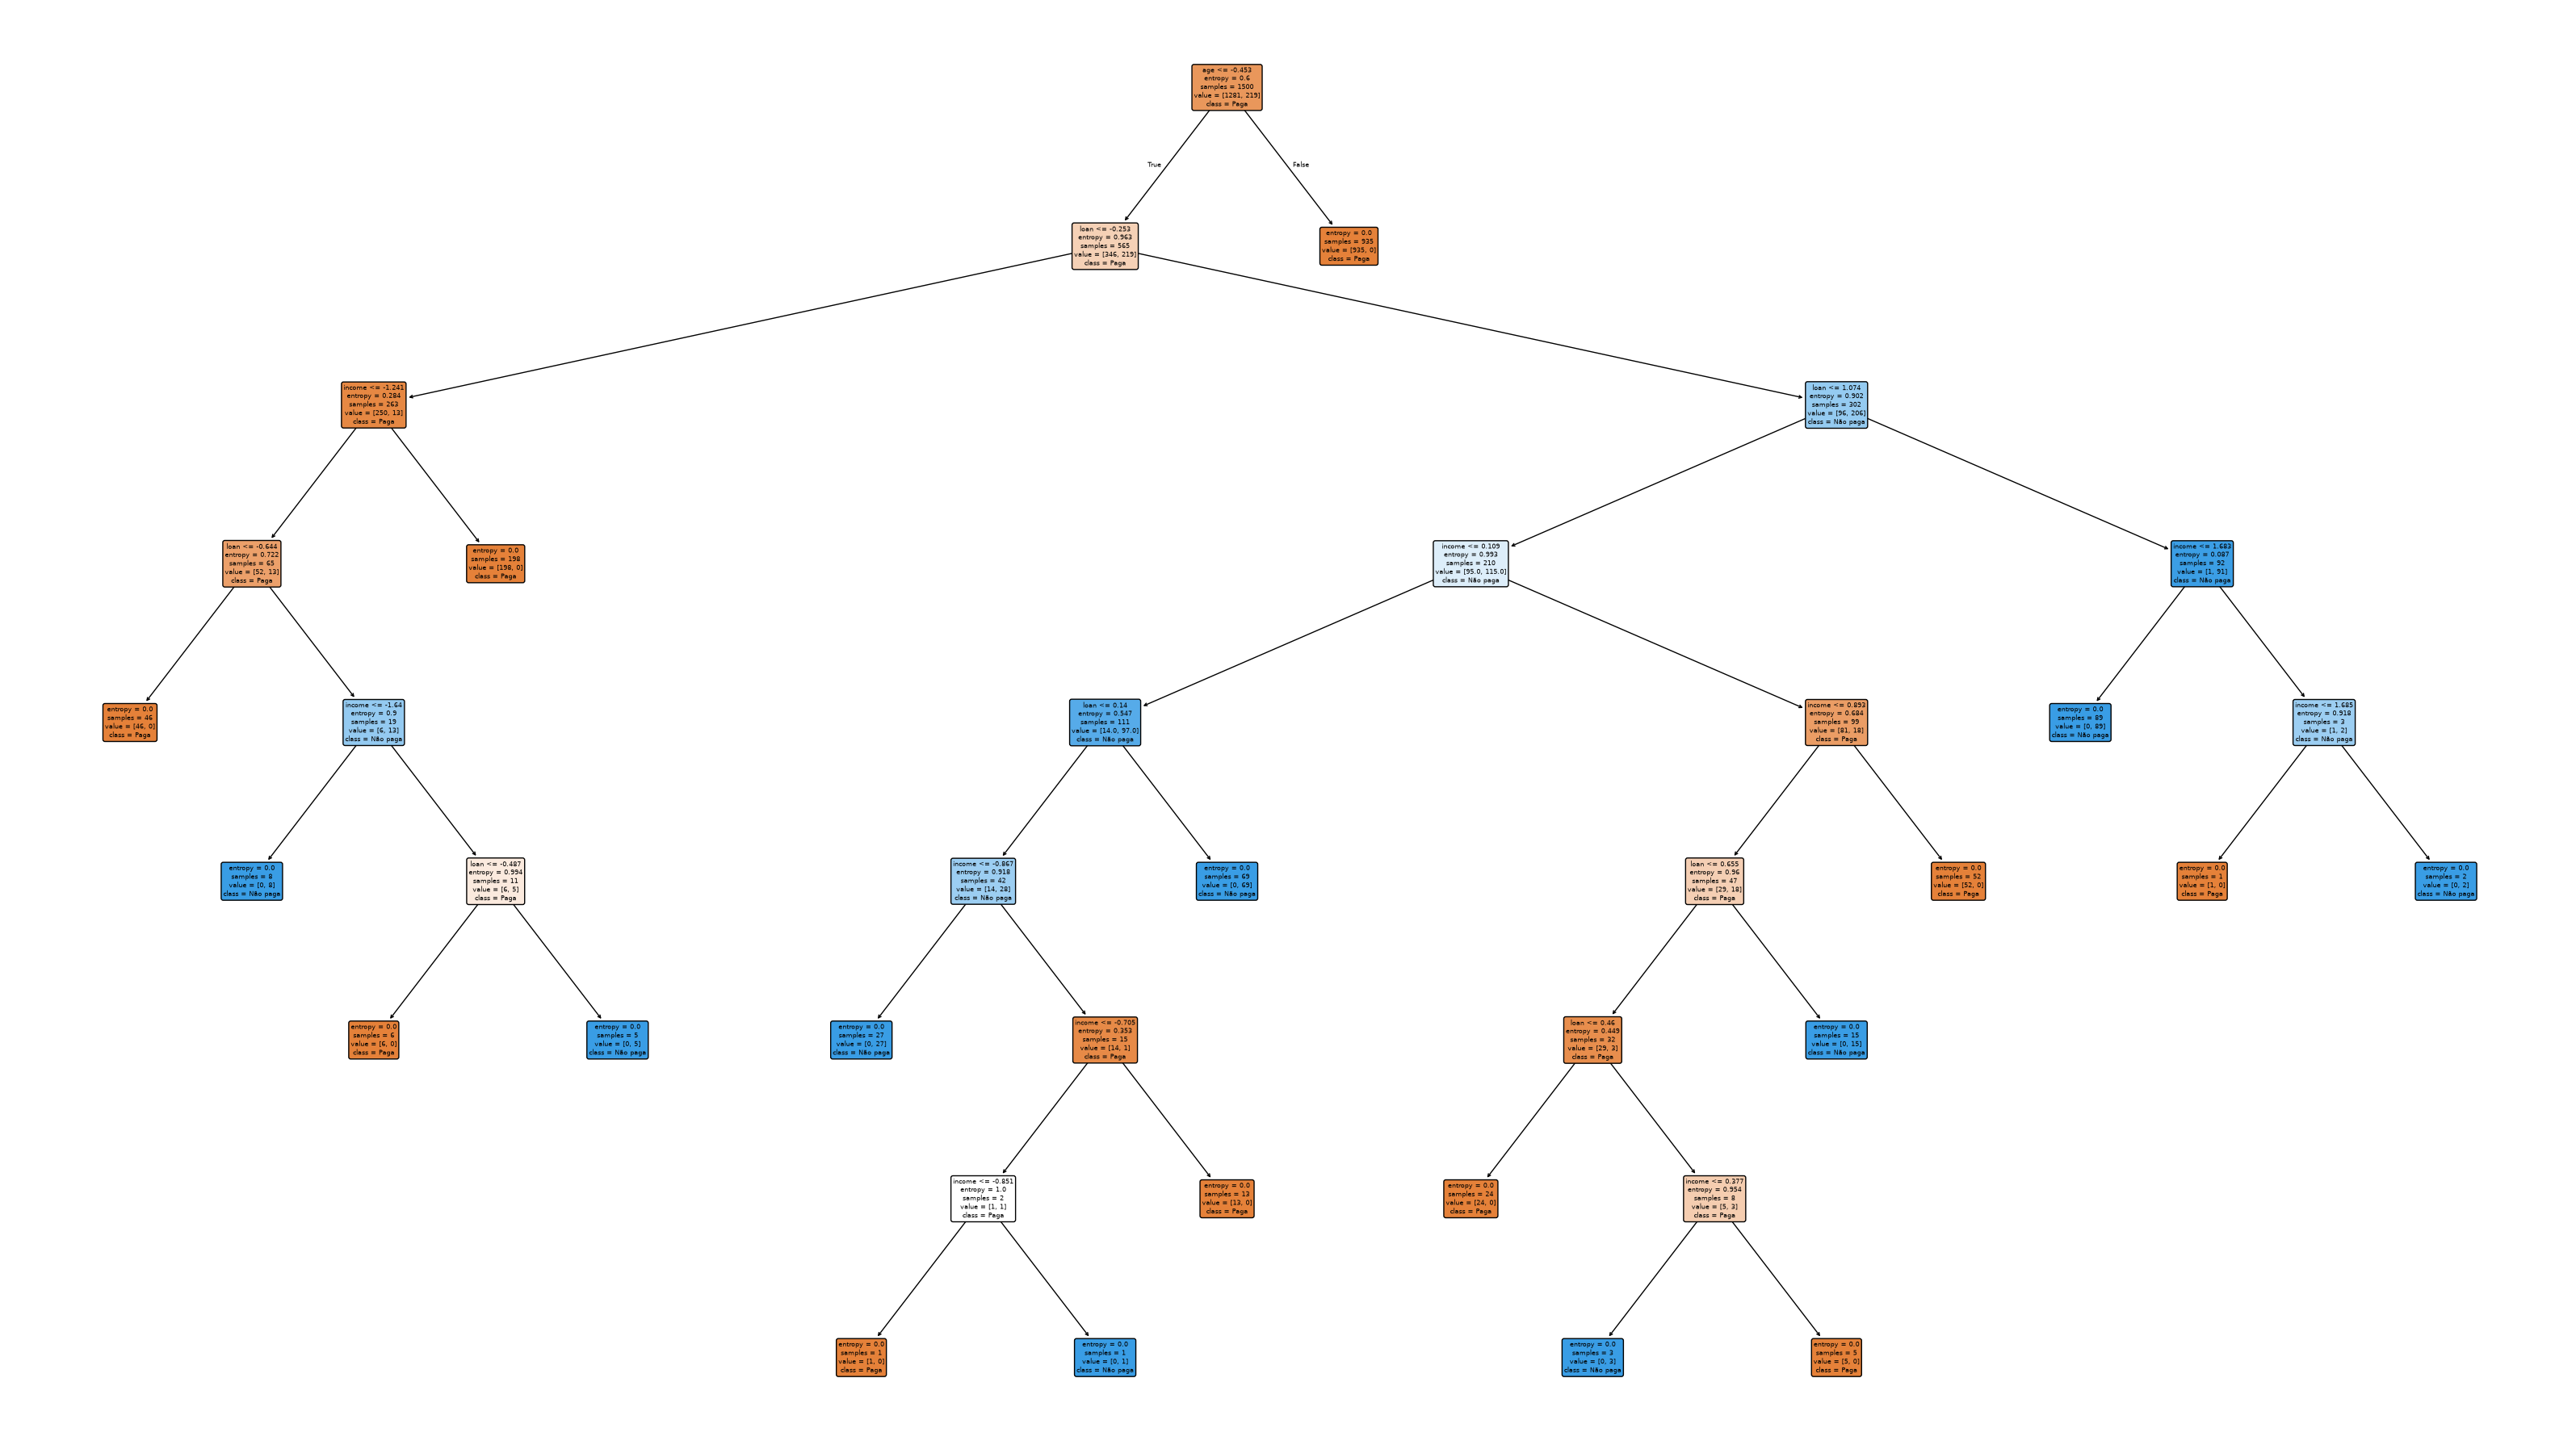

In [13]:
figura, eixo = plt.subplots(figsize=(32, 18))
tree.plot_tree(
    arvore_credit, feature_names=['income', 'age', 'loan'],
    class_names=['Paga', 'Não paga'], filled=True, rounded=True,
    fontsize=6, ax=eixo
)
figura.tight_layout()
figura.savefig(pasta_parte_2 / 'arvore_credit.png', dpi=140, bbox_inches='tight')
plt.show()

# 4 — Random Forest

## a) e b) Criação e treinamento com 10 árvores

In [14]:
random_forest_credit = RandomForestClassifier(
    n_estimators=10, criterion='entropy', random_state=0
)
random_forest_credit.fit(X_credit_treinamento, y_credit_treinamento)
print('Random Forest treinada com sucesso.')

Random Forest treinada com sucesso.


## c) Previsões

In [15]:
previsoes_forest = random_forest_credit.predict(X_credit_teste)
pd.DataFrame({
    'real': y_credit_teste,
    'previsao': previsoes_forest,
    'correto': y_credit_teste == previsoes_forest
}).head(20)

,real,previsao,correto
0,1,1,True
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


## d) Acurácia e comparação

In [16]:
acuracia_forest = accuracy_score(y_credit_teste, previsoes_forest)
print(f'Árvore de Decisão: {acuracia_arvore:.2%}')
print(f'Random Forest (10 árvores): {acuracia_forest:.2%}')
print('A Random Forest com 10 árvores foi melhor?', acuracia_forest > acuracia_arvore)

Árvore de Decisão: 98.20%
Random Forest (10 árvores): 96.80%
A Random Forest com 10 árvores foi melhor? False


Com 10 árvores, a Random Forest atingiu **96,8%**, abaixo dos **98,2%** da árvore simples. Isso não significa que Random Forest seja sempre inferior: o número reduzido de estimadores pode produzir uma floresta menos estável.

## e) Aumento do número de árvores

In [17]:
random_forest_credit_40 = RandomForestClassifier(
    n_estimators=40, criterion='entropy', random_state=0
)
random_forest_credit_40.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_forest_40 = random_forest_credit_40.predict(X_credit_teste)
acuracia_forest_40 = accuracy_score(y_credit_teste, previsoes_forest_40)

pd.DataFrame({
    'modelo': ['Árvore de Decisão', 'Random Forest (10)', 'Random Forest (40)'],
    'acuracia': [
        f'{acuracia_arvore:.2%}',
        f'{acuracia_forest:.2%}',
        f'{acuracia_forest_40:.2%}'
    ]
})

,modelo,acuracia
0,Árvore de Decisão,98.20%
1,Random Forest (10),96.80%
2,Random Forest (40),98.40%


Aumentar `n_estimators` de 10 para 40 reduziu a variância e elevou a acurácia para **98,4%**, superando a árvore simples. Mais árvores aumentam o custo computacional, e o melhor valor deve ser confirmado por validação.

## f) Matriz de confusão da Random Forest com 10 árvores

[[432   4]
 [ 12  52]]
Pagantes classificados corretamente: 432
Pagantes classificados como não pagantes: 4
Não pagantes classificados como pagantes: 12
Não pagantes classificados corretamente: 52


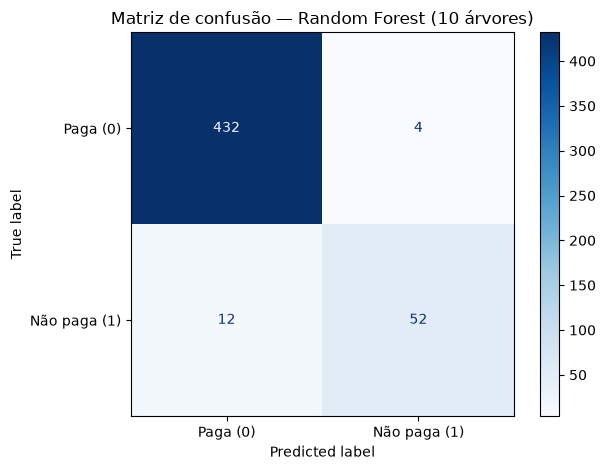

In [18]:
matriz_forest = confusion_matrix(y_credit_teste, previsoes_forest, labels=[0, 1])
vn_f, fp_f, fn_f, vp_f = matriz_forest.ravel()
print(matriz_forest)
print(f'Pagantes classificados corretamente: {vn_f}')
print(f'Pagantes classificados como não pagantes: {fp_f}')
print(f'Não pagantes classificados como pagantes: {fn_f}')
print(f'Não pagantes classificados corretamente: {vp_f}')

disp = ConfusionMatrixDisplay(matriz_forest, display_labels=['Paga (0)', 'Não paga (1)'])
disp.plot(cmap='Blues', values_format='d')
disp.ax_.set_title('Matriz de confusão — Random Forest (10 árvores)')
disp.figure_.tight_layout()
disp.figure_.savefig(pasta_parte_2 / 'matriz_confusao_random_forest.png', dpi=140, bbox_inches='tight')
plt.show()

## g) Relatório de classificação da Random Forest

In [19]:
print(classification_report(
    y_credit_teste, previsoes_forest,
    target_names=['Paga (0)', 'Não paga (1)'], digits=4
))

              precision    recall  f1-score   support

    Paga (0)     0.9730    0.9908    0.9818       436
Não paga (1)     0.9286    0.8125    0.8667        64

    accuracy                         0.9680       500
   macro avg     0.9508    0.9017    0.9242       500
weighted avg     0.9673    0.9680    0.9671       500



**Interpretação:** a classe 0 possui recall de aproximadamente 99,08%, mas a classe 1 possui recall de apenas 81,25%. Portanto, a floresta com 10 árvores deixa de identificar 12 dos 64 clientes que não pagam. Em concessão de crédito, esses falsos negativos podem ser especialmente custosos. A acurácia isolada não é suficiente; também é necessário observar precision, recall e a matriz de confusão.

# Conclusão

A Árvore de Decisão obteve 98,2% de acurácia. A Random Forest com 10 árvores obteve 96,8%, mas chegou a 98,4% com 40 árvores. A análise demonstra que os hiperparâmetros influenciam o resultado e que a avaliação deve considerar não apenas a acurácia, mas também os tipos de erro cometidos.